# 14 — Capítulo 9: todas las materias, penales incluidas
Los notebooks 09 a 13 trabajan sobre los capítulos 5 y 6 (detalle por tipo de proceso) y dejan fuera las materias penales,
que ahí no publican causas resueltas. El **capítulo 9** del Anuario resume el movimiento de causas por **materia** y por
**departamento** con las cinco cantidades completas, **también para las materias penales**: `pendientes_inicio`,
`ingresadas`, `atendidas`, `resueltas` y `pendientes_fin`. Con eso los indicadores del CEJA se pueden calcular para el
100 % de las causas, aunque a un nivel menos fino (materia × ámbito, sin tipo de proceso).

Este notebook solo **agrega** archivos nuevos en `data/curated/eda/`; no modifica ninguna tabla anterior.

| cuadro | ámbito | desagregación |
|---|---|---|
| 9.1.1 | capitales | materia |
| 9.1.5 | provincias | materia |
| 9.1.9 | nacional | materia |
| 9.1.3 · 9.1.7 · 9.1.11 | capitales · provincias · nacional | ciudad o departamento |

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/flujo.ipynb
import numpy as np
import matplotlib.pyplot as plt

OUT_EDA = CURATED / "eda"
OUT_EDA.mkdir(parents=True, exist_ok=True)

mov = pd.read_parquet(PROCESSED / "causas_movimiento.parquet")
discrepancias = pd.read_csv(PROCESSED / "auditoria" / "discrepancias.csv")
datos = mov[mov["tipo_fila_derivado"] == "dato"].copy()
totales = mov[mov["tipo_fila_derivado"] == "total"].copy()
print(len(datos), "filas de datos y", len(totales), "de total en", datos["cuadro_origen"].nunique(), "cuadros del capítulo 9")

72 filas de datos y 6 de total en 6 cuadros del capítulo 9


## Control 1: las identidades del movimiento
`atendidas = pendientes_inicio + ingresadas` y `atendidas = resueltas + pendientes_fin`. Las filas que no cierran tienen que
estar ya registradas como discrepancias de la fuente (`auditoria/discrepancias.csv`); una fila nueva que no cierre detiene el notebook.

In [2]:
datos["d_entrada"] = datos["pendientes_inicio"] + datos["ingresadas"] - datos["atendidas"]
datos["d_salida"] = datos["atendidas"] - datos["resueltas"] - datos["pendientes_fin"]
rotas = datos[(datos["d_entrada"] != 0) | (datos["d_salida"] != 0)]
registro = discrepancias[discrepancias["cuadro_origen"].astype(str).str.startswith("9.1")]
for _, f in rotas.iterrows():
    registrada = registro[(registro["cuadro_origen"] == f["cuadro_origen"]) &
                          (registro["entidad"].str.upper() == str(f["etiqueta_fila"]).upper())]
    assert len(registrada) > 0, "identidad rota y no registrada: " + str(f["cuadro_origen"]) + " " + str(f["etiqueta_fila"])
print(len(datos) - len(rotas), "de", len(datos), "filas cierran sus dos identidades;", len(rotas), "no cierran (diferencia de 1 causa, ya registradas)")
assert (rotas[["d_entrada", "d_salida"]].abs().max().max()) <= 1
rotas[["cuadro_origen", "etiqueta_fila", "d_entrada", "d_salida"]]

68 de 72 filas cierran sus dos identidades; 4 no cierran (diferencia de 1 causa, ya registradas)


,cuadro_origen,etiqueta_fila,d_entrada,d_salida
3,9.1.1,PARTIDO DE TRABAJO Y SEGURIDAD SOCIAL,1,0
18,9.1.3,El Alto,1,0
55,9.1.9,PARTIDO DE TRABAJO Y SEGURIDAD SOCIAL,1,0
69,9.1.11,La Paz,1,0


## Control 2: otro camino, capital + provincia = nacional
El Anuario publica los mismos datos tres veces (capitales, provincias, nacional). Si el capítulo está bien leído, la suma de
las dos primeras reproduce la tercera, materia por materia y columna por columna. Lo mismo por departamento: ciudades
capitales (9.1.3) + provincias (9.1.7) = nacional (9.1.11). Y la fila de total tiene que ser la suma de las filas.

In [3]:
mat = datos[datos["eje"] == "materia"]
por_ambito = {}
for ambito, cuadro in [("capital", "9.1.1"), ("provincia", "9.1.5"), ("nacional", "9.1.9")]:
    por_ambito[ambito] = mat[mat["cuadro_origen"] == cuadro].set_index("materia_homologada")[COLUMNAS_FLUJO]
dif = por_ambito["capital"].add(por_ambito["provincia"], fill_value=0).sub(por_ambito["nacional"], fill_value=0)
assert dif.abs().sum().sum() == 0, "capital + provincia no reproduce el nacional por materia"
print("materia: capital + provincia = nacional en las", len(por_ambito["nacional"]), "materias y las 5 columnas (0 diferencias)")

dep = datos[datos["eje"].isin(["ciudad", "departamento"])].copy()
# En el 9.1.3 (por ciudad) el departamento está en departamento_derivado; en 9.1.7 y 9.1.11, en departamento.
dep["depto"] = dep["departamento_derivado"].fillna(dep["departamento"])
assert dep["depto"].notna().all()
cap_dep = dep[dep["cuadro_origen"] == "9.1.3"].groupby("depto")[COLUMNAS_FLUJO].sum()
pro_dep = dep[dep["cuadro_origen"] == "9.1.7"].set_index("depto")[COLUMNAS_FLUJO]
nac_dep = dep[dep["cuadro_origen"] == "9.1.11"].set_index("depto")[COLUMNAS_FLUJO]
dif_dep = cap_dep.add(pro_dep, fill_value=0).sub(nac_dep, fill_value=0)
assert dif_dep.abs().max().max() <= 1, "ciudades + provincias no reproduce el nacional por departamento"
print("departamento: capitales + provincias = nacional en los", len(nac_dep), "departamentos (diferencia máxima:", int(dif_dep.abs().max().max()), ")")

for cuadro in ["9.1.1", "9.1.5", "9.1.9", "9.1.3", "9.1.7", "9.1.11"]:
    suma_filas = datos[datos["cuadro_origen"] == cuadro][COLUMNAS_FLUJO].sum()
    fila_total = totales[totales["cuadro_origen"] == cuadro][COLUMNAS_FLUJO].iloc[0]
    assert (suma_filas - fila_total).abs().max() <= 1, "la fila de total del " + cuadro + " no es la suma de sus filas"
print("las 6 filas de total son la suma de sus filas (diferencia máxima de 1 causa, registrada)")

materia: capital + provincia = nacional en las 15 materias y las 5 columnas (0 diferencias)
departamento: capitales + provincias = nacional en los 9 departamentos (diferencia máxima: 0 )
las 6 filas de total son la suma de sus filas (diferencia máxima de 1 causa, registrada)


## Indicadores por materia
Se agrupan los rótulos con el mapa cerrado de `modulos/flujo.ipynb` (los pares de anticorrupción y violencia con rótulos
invertidos entre cuadros se suman). **Ejecución penal** se separa como tipo propio: el propio Anuario aclara que esos
juzgados «no resuelven», así que sus tasas y su duración no son comparables con las de las demás materias.

In [4]:
base = asignar_grupo(mat)
grupos = base.groupby(["ambito", "grupo_materia", "tipo_materia"], as_index=False)[COLUMNAS_FLUJO].sum()
ind = indicadores_flujo(grupos)
orden_tipo = {NO_PENAL: 0, PENAL: 1, EJECUCION: 2}
ind["_o"] = ind["tipo_materia"].map(orden_tipo)
ind = ind.sort_values(["ambito", "_o", "duracion_estimada_dias"], ascending=[True, True, False]).drop(columns="_o").reset_index(drop=True)
ind.to_csv(OUT_EDA / "indicadores_capitulo9_materia.csv", index=False, encoding="utf-8")

nac = ind[ind["ambito"] == "nacional"].copy()
assert len(nac) == 13, "se esperaban 13 grupos de materia"
total_nac = nac[COLUMNAS_FLUJO].sum()
fila = totales[totales["cuadro_origen"] == "9.1.9"][COLUMNAS_FLUJO].iloc[0]
assert (total_nac - fila).abs().max() <= 1
print("13 grupos de materia; el total nacional reproduce la fila de total del 9.1.9")
cols = ["grupo_materia", "tipo_materia", "pendientes_inicio", "ingresadas", "resueltas", "pendientes_fin",
        "tasa_resolucion", "tasa_congestion", "duracion_estimada_dias", "variacion_stock", "variacion_stock_pct", "banda_resolucion_ceja"]
nac[cols].round(2)

13 grupos de materia; el total nacional reproduce la fila de total del 9.1.9


,grupo_materia,tipo_materia,pendientes_inicio,ingresadas,resueltas,pendientes_fin,tasa_resolucion,tasa_congestion,duracion_estimada_dias,variacion_stock,variacion_stock_pct,banda_resolucion_ceja
13,Coactivo Fiscal y Tributario,no penal,11237,2012,2671,10578,1.33,4.96,1445.51,-659.0,-5.86,óptima
14,Trabajo y Seguridad Social,no penal,27269,24073,23441,27900,0.97,2.19,434.43,631.0,2.31,mejorable
15,Niñez y Adolescencia,no penal,6097,12162,11712,6547,0.96,1.56,204.03,450.0,7.38,mejorable
16,Familia,no penal,42117,78366,79210,41273,1.01,1.52,190.19,-844.0,-2.00,óptima
17,Civil y Comercial,no penal,43062,93812,94769,42105,1.01,1.44,162.17,-957.0,-2.22,óptima
18,Tribunales de sentencia penal,penal,9416,2083,1811,9688,0.87,6.35,1952.58,272.0,2.89,crítica
19,Tribunal de sentencia: anticorrupción + violencia,penal,5837,2606,1964,6479,0.75,4.30,1204.09,642.0,11.00,crítica
20,Sentencia: anticorrupción + violencia,penal,13727,9112,6031,16808,0.66,3.79,1017.23,3081.0,22.44,crítica
21,Sentencia penal,penal,35434,17878,16457,36855,0.92,3.24,817.41,1421.0,4.01,mejorable
22,Instrucción anticorrupción,penal,2678,2325,2192,2811,0.94,2.28,468.07,133.0,4.97,mejorable


## De dónde viene el cambio del stock en 2023
`variación = pendientes_fin − pendientes_inicio`, dentro del año. Ojo: es la variación **dentro de 2023**. El notebook 15 muestra
que el stock de apertura de un año no coincide con el cierre del anterior.

In [5]:
por_tipo = nac.groupby("tipo_materia")[COLUMNAS_FLUJO].sum()
por_tipo["variacion_stock"] = por_tipo["pendientes_fin"] - por_tipo["pendientes_inicio"]
por_tipo["atendidas_pct"] = por_tipo["atendidas"] / por_tipo["atendidas"].sum() * 100
por_tipo = indicadores_flujo(por_tipo.reset_index()).set_index("tipo_materia")
variacion_total = int(nac["variacion_stock"].sum())
assert variacion_total == int(fila["pendientes_fin"] - fila["pendientes_inicio"])
print("variación del stock en 2023:", miles(variacion_total, signo=True))
for tipo in [NO_PENAL, PENAL, EJECUCION]:
    print("  {:<16} {:>8}".format(tipo, miles(por_tipo.loc[tipo, "variacion_stock"], signo=True)))
por_tipo[["pendientes_inicio", "ingresadas", "resueltas", "pendientes_fin", "variacion_stock", "tasa_resolucion", "tasa_congestion", "atendidas_pct"]].round(2)

variación del stock en 2023: +19.114
  no penal           −1.379
  penal             +13.134
  ejecución penal    +7.359


,pendientes_inicio,ingresadas,resueltas,pendientes_fin,variacion_stock,tasa_resolucion,tasa_congestion,atendidas_pct
tipo_materia,,,,,,,,
ejecución penal,37907,16427,9068,45266,7359.0,0.55,5.99,7.35
no penal,129782,210425,211803,128403,-1379.0,1.01,1.61,46.05
penal,169705,174596,161462,182839,13134.0,0.92,2.13,46.6


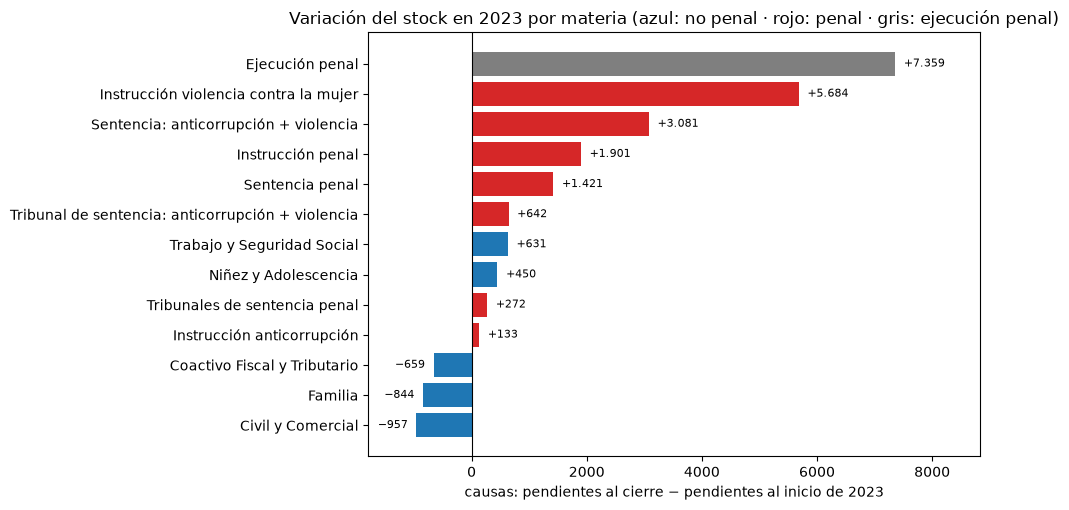

In [6]:
colores = {NO_PENAL: "tab:blue", PENAL: "tab:red", EJECUCION: "tab:gray"}
t = nac.sort_values("variacion_stock")
fig, ax = plt.subplots(figsize=(10, 5.2))
barras = ax.barh(t["grupo_materia"], t["variacion_stock"], color=[colores[x] for x in t["tipo_materia"]])
for b, v in zip(barras, t["variacion_stock"]):
    ax.text(v + (150 if v >= 0 else -150), b.get_y() + b.get_height() / 2, miles(v, signo=True),
            va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("causas: pendientes al cierre − pendientes al inicio de 2023")
ax.set_title("Variación del stock en 2023 por materia (azul: no penal · rojo: penal · gris: ejecución penal)")
ax.set_xlim(t["variacion_stock"].min() * 1.35 - 500, t["variacion_stock"].max() * 1.2)
plt.tight_layout()
plt.show()

## Tasa de resolución y días para vaciar el stock
La tasa de resolución usa los umbrales del CEJA (≥ 1,00 óptima, 0,90 a 0,99 mejorable, < 0,90 crítica). Los días para vaciar son
`pendientes_fin ÷ resueltas × 365`, el mismo estimador del resto del proyecto. Ejecución penal va aparte y no entra en el ranking.

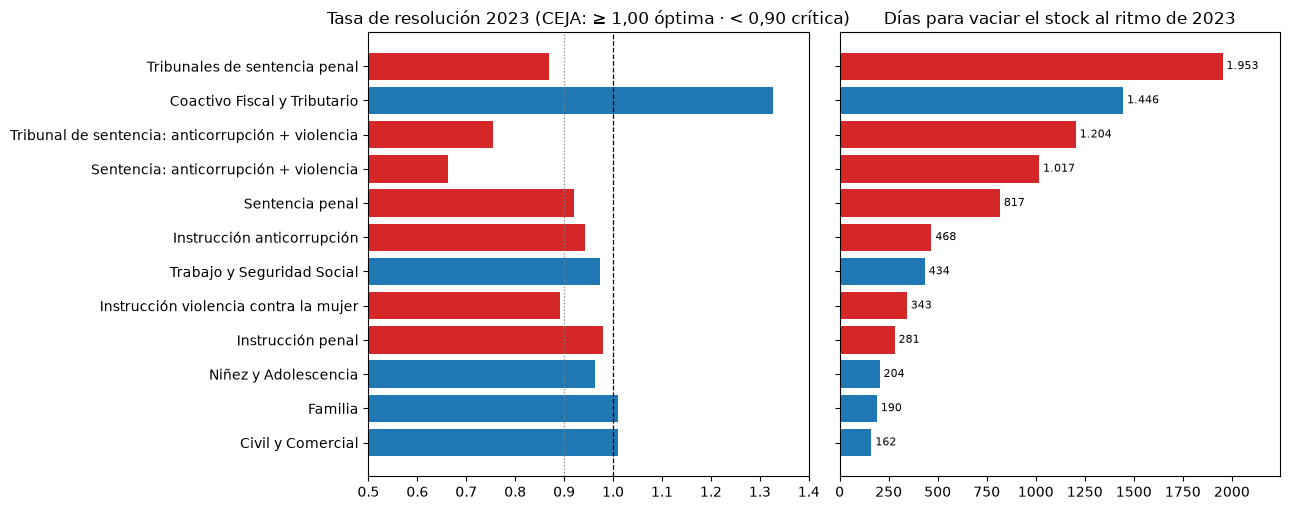

Ejecución penal (no comparable, el Anuario dice que esos juzgados no resuelven): resolución 0.55, stock +7.359 (+19.4 %)


In [7]:
comparables = nac[nac["tipo_materia"] != EJECUCION].sort_values("duracion_estimada_dias")
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
ejes[0].barh(comparables["grupo_materia"], comparables["tasa_resolucion"], color=[colores[x] for x in comparables["tipo_materia"]])
ejes[0].axvline(1.0, color="black", linestyle="--", linewidth=0.9)
ejes[0].axvline(0.9, color="gray", linestyle=":", linewidth=0.9)
ejes[0].set_xlim(0.5, 1.4)
ejes[0].set_title("Tasa de resolución 2023 (CEJA: ≥ 1,00 óptima · < 0,90 crítica)")
ejes[1].barh(comparables["grupo_materia"], comparables["duracion_estimada_dias"], color=[colores[x] for x in comparables["tipo_materia"]])
ejes[1].set_title("Días para vaciar el stock al ritmo de 2023")
for b, v in zip(ejes[1].patches, comparables["duracion_estimada_dias"]):
    ejes[1].text(v + 20, b.get_y() + b.get_height() / 2, miles(v), va="center", fontsize=8)
ejes[1].set_xlim(0, comparables["duracion_estimada_dias"].max() * 1.15)
plt.tight_layout()
plt.show()
ej = nac[nac["tipo_materia"] == EJECUCION].iloc[0]
print("Ejecución penal (no comparable, el Anuario dice que esos juzgados no resuelven): resolución {:.2f}, stock {} ({:+.1f} %)".format(
    ej["tasa_resolucion"], miles(ej["variacion_stock"], signo=True), ej["variacion_stock_pct"]))

## Por departamento, todas las materias
El cuadro 9.1.11 resume el movimiento de todas las materias por departamento (capital + provincias). Es una lectura distinta a la
del notebook 12, que cubre solo la justicia no penal.

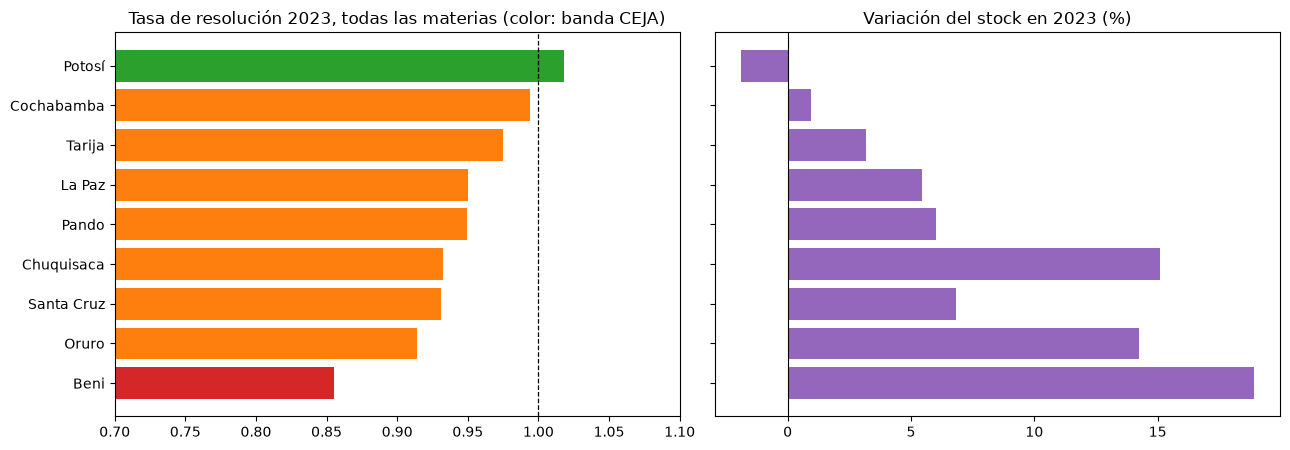

,departamento,pendientes_inicio,ingresadas,resueltas,pendientes_fin,tasa_resolucion,tasa_congestion,duracion_estimada_dias,variacion_stock_pct,banda_resolucion_ceja
0,Beni,11798,15384,13152,14030,0.85,2.07,389.37,18.92,crítica
1,Oruro,13641,22628,20685,15584,0.91,1.75,274.99,14.24,mejorable
2,Santa Cruz,111624,110723,103096,119251,0.93,2.16,422.19,6.83,mejorable
3,Chuquisaca,9970,22286,20782,11474,0.93,1.55,201.52,15.09,mejorable
4,Pando,4473,5304,5035,4742,0.95,1.94,343.76,6.01,mejorable
5,La Paz,89133,97932,93080,93984,0.95,2.01,368.54,5.44,mejorable
6,Tarija,23154,28947,28211,23890,0.97,1.85,309.09,3.18,mejorable
7,Cochabamba,47802,71099,70656,48245,0.99,1.68,249.23,0.93,mejorable
8,Potosí,25799,27145,27636,25308,1.02,1.92,334.25,-1.90,óptima


In [8]:
dep_ind = indicadores_flujo(nac_dep.reset_index().rename(columns={"depto": "departamento"}))
dep_ind = dep_ind.sort_values("tasa_resolucion").reset_index(drop=True)
dep_ind.to_csv(OUT_EDA / "indicadores_capitulo9_departamento.csv", index=False, encoding="utf-8")
assert len(dep_ind) == 9
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
color_banda = {"óptima": "tab:green", "mejorable": "tab:orange", "crítica": "tab:red"}
ejes[0].barh(dep_ind["departamento"], dep_ind["tasa_resolucion"], color=[color_banda[b] for b in dep_ind["banda_resolucion_ceja"]])
ejes[0].axvline(1.0, color="black", linestyle="--", linewidth=0.9)
ejes[0].set_xlim(0.7, 1.1)
ejes[0].set_title("Tasa de resolución 2023, todas las materias (color: banda CEJA)")
ejes[1].barh(dep_ind["departamento"], dep_ind["variacion_stock_pct"], color="tab:purple")
ejes[1].axvline(0, color="black", linewidth=0.8)
ejes[1].set_title("Variación del stock en 2023 (%)")
plt.tight_layout()
plt.show()
dep_ind[["departamento", "pendientes_inicio", "ingresadas", "resueltas", "pendientes_fin", "tasa_resolucion", "tasa_congestion",
         "duracion_estimada_dias", "variacion_stock_pct", "banda_resolucion_ceja"]].round(2)

## Brecha de capacidad (aritmética, no un modelo)
Cuántas resoluciones más al año harían falta para (a) **frenar el crecimiento** del stock dentro del año, `max(0, ingresadas − resueltas)`,
y (b) **vaciar el stock en tres años**, lo anterior más `pendientes_fin ÷ 3`. Se expresa como porcentaje de lo que hoy se resuelve.
Es un orden de magnitud, no una proyección: el stock publicado no se conserva entre años (notebook 15).

In [9]:
cap = nac[["grupo_materia", "tipo_materia", "resueltas", "pendientes_fin", "resoluciones_extra_para_frenar",
           "resoluciones_extra_para_vaciar_3_anios", "pct_extra_para_vaciar_3_anios"]].copy()
total = pd.DataFrame([{"pendientes_inicio": nac["pendientes_inicio"].sum(), "ingresadas": nac["ingresadas"].sum(), "atendidas": nac["atendidas"].sum(),
                       "resueltas": nac["resueltas"].sum(), "pendientes_fin": nac["pendientes_fin"].sum()}])
total = indicadores_flujo(total).iloc[0]
cap.loc[len(cap)] = ["TODAS LAS MATERIAS", "todas", total["resueltas"], total["pendientes_fin"], total["resoluciones_extra_para_frenar"],
                     total["resoluciones_extra_para_vaciar_3_anios"], total["pct_extra_para_vaciar_3_anios"]]
cap.to_csv(OUT_EDA / "capacidad_resoluciones_extra.csv", index=False, encoding="utf-8")
print("Para frenar el crecimiento hacen falta {} resoluciones más al año ({:.1f} % más); para vaciar el stock en 3 años, {} ({:.0f} % más).".format(
    miles(total["resoluciones_extra_para_frenar"]), total["resoluciones_extra_para_frenar"] / total["resueltas"] * 100,
    miles(total["resoluciones_extra_para_vaciar_3_anios"]), total["pct_extra_para_vaciar_3_anios"]))
cap.round(1)

Para frenar el crecimiento hacen falta 19.115 resoluciones más al año (5.0 % más); para vaciar el stock en 3 años, 137.951 (36 % más).


,grupo_materia,tipo_materia,resueltas,pendientes_fin,resoluciones_extra_para_frenar,resoluciones_extra_para_vaciar_3_anios,pct_extra_para_vaciar_3_anios
13,TODAS LAS MATERIAS,todas,382333,356508,19115.0,137951.0,36.1
14,Trabajo y Seguridad Social,no penal,23441,27900,632.0,9932.0,42.4
15,Niñez y Adolescencia,no penal,11712,6547,450.0,2632.3,22.5
16,Familia,no penal,79210,41273,0.0,13757.7,17.4
17,Civil y Comercial,no penal,94769,42105,0.0,14035.0,14.8
18,Tribunales de sentencia penal,penal,1811,9688,272.0,3501.3,193.3
19,Tribunal de sentencia: anticorrupción + violencia,penal,1964,6479,642.0,2801.7,142.7
20,Sentencia: anticorrupción + violencia,penal,6031,16808,3081.0,8683.7,144.0
21,Sentencia penal,penal,16457,36855,1421.0,13706.0,83.3
22,Instrucción anticorrupción,penal,2192,2811,133.0,1070.0,48.8


## Cobertura
Con el capítulo 9 los indicadores cubren todas las causas atendidas, no solo el 47,5 % de los notebooks 10 a 12.

In [10]:
cobertura = nac.groupby("tipo_materia")["atendidas"].sum()
print((cobertura / cobertura.sum() * 100).round(1).to_string())
curado = pd.read_parquet(CURATED / "features" / "dataset_analitico_curado.parquet")
proc = curado[curado["tipo_elemento_analitico"] == "proceso"]
print("\nCausas atendidas no penales: capítulo 9 = {}; detalle por tipo de proceso (capítulos 5 y 6) = {}".format(
    miles(cobertura[NO_PENAL]), miles(proc["atendidas"].sum())))
cobertura

tipo_materia
ejecución penal     7.4
no penal           46.0
penal              46.6

Causas atendidas no penales: capítulo 9 = 340.206; detalle por tipo de proceso (capítulos 5 y 6) = 335.472


tipo_materia
ejecución penal     54334
no penal           340206
penal              344301
Name: atendidas, dtype: Int64